## Step 1: Solve an ODE with a PINN

**Problem** ($x \in (0,1)$)

$$u'(x) + u(x) = \frac{1}{1+x}, \qquad u(0) = 1$$

**Exact solution:** $u(x) =  e^{-x}\left(1 + e^{-1}(\textrm{Ei}(x+1) - \textrm{Ei}(1))\right)$

---

## PINN idea

1. Use a neural network $u_\theta(x)$ as the approximate solution  
2. Minimize the PDE residual $|u' + u - 1/(1+x)|^2$ at **collocation points**  
3. Minimize $|u(0)-1|^2$ at the **boundary** $x=0$  
4. Compute $u'$ with PyTorch **automatic differentiation** (`autograd`)

Loss: $\mathcal{L} = \mathcal{L}_{\mathrm{PDE}} + \lambda_{\mathrm{BC}} \mathcal{L}_{\mathrm{BC}}$

Run the cells from top to bottom.

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from scipy.special import expi

def set_seed(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)

class MLP(nn.Module):
    """input x -> output u all-to-all (Tanh activation)"""
    def __init__(self, d_in=1, d_out=1, width=32, depth=4):
        super().__init__()
        layers = [nn.Linear(d_in, width), nn.Tanh()]
        for _ in range(depth - 1):
            layers += [nn.Linear(width, width), nn.Tanh()]
        layers.append(nn.Linear(width, d_out))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

def grad(y, x):
    """dy/dx (autograd)"""
    return torch.autograd.grad(
        y, x,
        grad_outputs=torch.ones_like(y),
        create_graph=True,
        retain_graph=True,
    )[0]

def relative_l2(pred, ref):
    return np.linalg.norm(pred - ref) / (np.linalg.norm(ref) + 1e-12)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cpu


## Hyperparameters

| Symbol | Meaning |
|------|------|
| `N_COLLOC` | Number of interior (PDE) points |
| `W_BC` | Weight of boundary loss $\lambda_{\mathrm{BC}}$ |
| `EPOCHS` | Number of training epochs |

If training is unstable, a common fix is to **increase `W_BC`**.

In [16]:
X_MIN, X_MAX = 0.0, 1.0
N_COLLOC = 200
EPOCHS = 5000
LR = 1e-3
W_BC = 100.0

def exact_u(x):
    """u(x) = e^{-x} (1 + e^{-1} (Ei(x+1) - Ei(1)))"""
    return np.exp(-x) * (1.0 + np.exp(-1.0) * (expi(x + 1.0) - expi(1.0)))

## Training loop

- `x_int`: Points where the PDE residual is evaluated (`requires_grad=True` is required)
- `res = du_dx + u_int - 1/(1+x_int)`: Residual of $u'+u=1/(1+x)$

In [17]:
model = MLP(width=32, depth=4).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

x_int = torch.linspace(X_MIN + 1e-3, X_MAX, N_COLLOC, device=device).view(-1, 1)
x_int.requires_grad_(True)
x0 = torch.zeros(1, 1, device=device)
u0_target = torch.ones(1, 1, device=device)

x_plot = torch.linspace(X_MIN, X_MAX, 300, device=device).view(-1, 1)
snap_epochs = {0, 100, 500, 1000, 2000, EPOCHS}

def snapshot():
    with torch.no_grad():
        return model(x_plot).detach().cpu().numpy().ravel().copy()

history = []
snapshots = {0: snapshot()}  # untrained network
for epoch in range(EPOCHS):
    optimizer.zero_grad()

    u_int = model(x_int)
    du_dx = grad(u_int, x_int)
    res = du_dx + u_int - 1.0 / (1.0 + x_int)
    loss_pde = torch.mean(res ** 2)

    u0 = model(x0)
    loss_bc = torch.mean((u0 - u0_target) ** 2)

    loss = loss_pde + W_BC * loss_bc
    loss.backward()
    optimizer.step()
    history.append(loss.item())

    if (epoch + 1) in snap_epochs:
        snapshots[epoch + 1] = snapshot()
    if (epoch + 1) % 1000 == 0:
        print(
            f"epoch {epoch+1:5d}  loss={loss.item():.3e}  "
            f"pde={loss_pde.item():.3e}  bc={loss_bc.item():.3e}"
        )

epoch  1000  loss=4.642e-04  pde=4.640e-04  bc=2.519e-09
epoch  2000  loss=7.553e-05  pde=7.553e-05  bc=6.571e-11
epoch  3000  loss=4.297e-05  pde=4.297e-05  bc=2.402e-12
epoch  4000  loss=3.246e-05  pde=3.246e-05  bc=1.421e-14
epoch  5000  loss=2.683e-05  pde=2.683e-05  bc=6.963e-13


## Visualize results and evaluate error

relative L2 error: 5.5620e-04


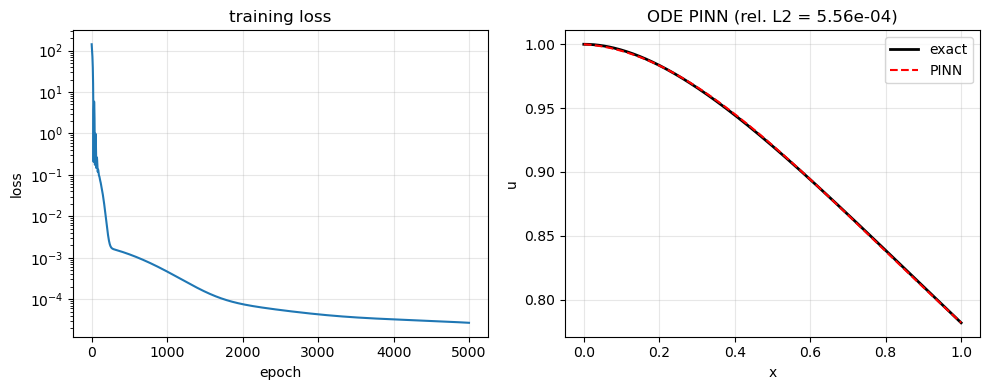

In [20]:
x_test = np.linspace(X_MIN, X_MAX, 300)
x_t = torch.tensor(x_test, dtype=torch.float32, device=device).view(-1, 1)
with torch.no_grad():
    u_pred = model(x_t).cpu().numpy().ravel()
u_ref = exact_u(x_test)
err = relative_l2(u_pred, u_ref)
print(f"relative L2 error: {err:.4e}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].semilogy(history)
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].set_title("training loss")
axes[0].grid(True, alpha=0.3)

axes[1].plot(x_test, u_ref, "k-", lw=2, label="exact")
axes[1].plot(x_test, u_pred, "r--", lw=1.5, label="PINN")
axes[1].set_xlabel("x")
axes[1].set_ylabel("u")
axes[1].set_title(f"ODE PINN (rel. L2 = {err:.2e})")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Exercises (optional)

1. Change `W_BC` to `10` or `500` and observe how the solution changes  
2. Error when `EPOCHS` is reduced to `1000`  
3. Continue to the next notebook `02_poisson_1d_pinn.ipynb` (elliptic PDE, second derivatives)

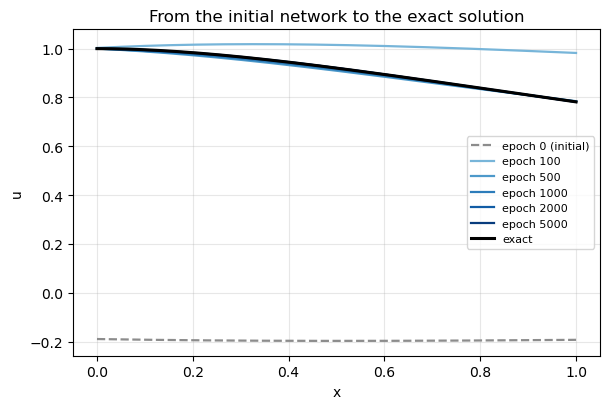

In [19]:
x_snap = x_plot.detach().cpu().numpy().ravel()
u_exact = exact_u(x_snap)
epochs_sorted = sorted(snapshots)

fig, ax = plt.subplots(figsize=(6.2, 4.2))
colors = plt.cm.Blues(np.linspace(0.35, 0.95, len(epochs_sorted)))
for color, ep in zip(colors, epochs_sorted):
    if ep == 0:
        ax.plot(x_snap, snapshots[ep], color="0.55", ls="--", lw=1.6, label="epoch 0 (initial)")
    else:
        ax.plot(x_snap, snapshots[ep], color=color, lw=1.6, label=f"epoch {ep}")
ax.plot(x_snap, u_exact, "k-", lw=2.2, label="exact")
ax.set_xlabel("x")
ax.set_ylabel("u")
ax.set_title("From the initial network to the exact solution")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()